## Comparison model

The comparison uses the same U-Net model with an ImageNet-pretrained ResNet18
encoder as the baseline. We replace BCEWithLogitsLoss with a combined BCE + Dice
loss to investigate whether an overlap-based objective improves building
segmentation. The dataset, preprocessing and training settings remain unchanged.


In [1]:
import torch

print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("GPU required for this run. Select the project .venv kernel and check nvidia-smi.")
print("GPU:", torch.cuda.get_device_name(0))


CUDA available: True
GPU: NVIDIA GeForce RTX 5070


In [2]:
from pathlib import Path

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/preprocessing.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook inside CV-P22-building-segmentation.")


In [3]:
import os
import sys
import time
import subprocess
from datetime import datetime, timezone


os.environ.setdefault("TORCH_HOME", str(PROJECT_ROOT / ".cache" / "torch"))
os.environ.setdefault("HF_HOME", str(PROJECT_ROOT / ".cache" / "huggingface"))
import segmentation_models_pytorch as smp

sys.path.insert(0, str(PROJECT_ROOT))
from src.preprocessing import load_and_preprocess
from src.losses import BCEDiceLoss
from src.comparison_support import validate_comparison_data, runtime_environment, write_json, sha256

RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()
ENVIRONMENT = runtime_environment(PROJECT_ROOT)


/home/obsessedume/Documents/св проект/CV-P22-building-segmentation/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
import pandas as pd

SPLITS_DIR = PROJECT_ROOT / "data" / "splits"

train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "val.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")


DATA_SUMMARY = validate_comparison_data(
    PROJECT_ROOT, {"train": train_df, "val": val_df, "test": test_df}
)
pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Patches": [len(train_df), len(val_df), len(test_df)],
})


,Split,Patches
0,Train,4932
1,Validation,144
2,Test,360


In [5]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


In [6]:
from torch.utils.data import Dataset, DataLoader


class BuildingDataset(Dataset):
    def __init__(self, dataframe, project_root):
        self.dataframe = dataframe.reset_index(drop=True)
        self.project_root = project_root

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = self.project_root / row["image_path"]
        mask_path = self.project_root / row["mask_path"]

        image, mask = load_and_preprocess(
            image_path,
            mask_path
        )

        return image, mask


In [7]:
train_dataset = BuildingDataset(train_df, PROJECT_ROOT)
val_dataset = BuildingDataset(val_df, PROJECT_ROOT)
test_dataset = BuildingDataset(test_df, PROJECT_ROOT)


In [8]:
BATCH_SIZE = 8

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    generator=generator

)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


In [9]:
images, masks = next(iter(train_loader))


In [10]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


In [11]:
model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
)

model = model.to(device)


In [12]:
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(images)

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Outputs:", outputs.shape)


Images: torch.Size([8, 3, 256, 256])
Masks: torch.Size([8, 1, 256, 256])
Outputs: torch.Size([8, 1, 256, 256])


## BCE + Dice loss

The loss is the sum of BCEWithLogitsLoss and soft Dice loss, with equal
coefficients. Dice is calculated from sigmoid probabilities for each patch and
averaged over the batch. Smoothing is 1, including for background-only patches.
The checkpoint is selected using the lowest validation combined loss.


In [13]:
import pandas as pd
import torch


criterion = BCEDiceLoss(smooth=1.0)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)


def compute_segmentation_stats(logits, targets, threshold=0.5):
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= threshold).float()

    intersection = (predictions * targets).sum().item()

    prediction_sum = predictions.sum().item()
    target_sum = targets.sum().item()

    union = prediction_sum + target_sum - intersection

    return intersection, union, prediction_sum, target_sum


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0

    total_intersection = 0.0
    total_union = 0.0
    total_prediction_sum = 0.0
    total_target_sum = 0.0


    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        intersection, union, pred_sum, target_sum = (
            compute_segmentation_stats(
                outputs.detach(),
                masks
            )
        )

        total_intersection += intersection
        total_union += union
        total_prediction_sum += pred_sum
        total_target_sum += target_sum


    average_loss = total_loss / len(loader.dataset)

    iou = (
        total_intersection
        / (total_union + 1e-7)
    )

    dice = (
        2 * total_intersection
        / (
            total_prediction_sum
            + total_target_sum
            + 1e-7
        )
    )

    return average_loss, iou, dice


def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0

    total_intersection = 0.0
    total_union = 0.0
    total_prediction_sum = 0.0
    total_target_sum = 0.0


    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, masks)

            total_loss += loss.item() * images.size(0)

            intersection, union, pred_sum, target_sum = (
                compute_segmentation_stats(
                    outputs,
                    masks
                )
            )

            total_intersection += intersection
            total_union += union
            total_prediction_sum += pred_sum
            total_target_sum += target_sum

    average_loss = total_loss / len(loader.dataset)

    iou = (
        total_intersection
        / (total_union + 1e-7)
    )

    dice = (
        2 * total_intersection
        / (
            total_prediction_sum
            + total_target_sum
            + 1e-7
        )
    )

    return average_loss, iou, dice


NUM_EPOCHS = 10

history = []

best_val_loss = float("inf")

MODEL_PATH = (
    PROJECT_ROOT
    / "results"
    / "comparison_unet_resnet18.pt"
)

METRICS_DIR = (
    PROJECT_ROOT
    / "results"
    / "metrics"
)

MODEL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def synchronize():
    torch.cuda.synchronize()


synchronize()
training_started = time.perf_counter()


for epoch in range(1, NUM_EPOCHS + 1):

    print(f"\nEpoch {epoch}/{NUM_EPOCHS}")

    synchronize()
    epoch_started = time.perf_counter()
    train_loss, train_iou, train_dice = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_iou, val_dice = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    synchronize()
    epoch_seconds = time.perf_counter() - epoch_started
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_iou": train_iou,
        "train_dice": train_dice,
        "val_loss": val_loss,
        "val_iou": val_iou,
        "val_dice": val_dice,
        "epoch_seconds": epoch_seconds,
    })

    print(
        f"Train loss: {train_loss:.4f} | "
        f"Train IoU: {train_iou:.4f} | "
        f"Train Dice: {train_dice:.4f}"
    )

    print(
        f"Val loss:   {val_loss:.4f} | "
        f"Val IoU:   {val_iou:.4f} | "
        f"Val Dice:  {val_dice:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            MODEL_PATH
        )


    pd.DataFrame(history).to_csv(METRICS_DIR / "comparison_training_history.csv", index=False)


synchronize()
training_seconds = time.perf_counter() - training_started
print(f"Training and validation time: {training_seconds:.1f} s")


history_df = pd.DataFrame(history)

history_df.to_csv(
    METRICS_DIR / "comparison_training_history.csv",
    index=False
)

print("\nTraining finished.")
print("Best validation loss:", round(best_val_loss, 4))



Epoch 1/10
Train loss: 0.7458 | Train IoU: 0.4817 | Train Dice: 0.6502
Val loss:   0.5942 | Val IoU:   0.5244 | Val Dice:  0.6880

Epoch 2/10
Train loss: 0.6567 | Train IoU: 0.5272 | Train Dice: 0.6904
Val loss:   0.5373 | Val IoU:   0.5549 | Val Dice:  0.7137

Epoch 3/10
Train loss: 0.6115 | Train IoU: 0.5398 | Train Dice: 0.7011
Val loss:   0.5405 | Val IoU:   0.5632 | Val Dice:  0.7206

Epoch 4/10
Train loss: 0.5952 | Train IoU: 0.5456 | Train Dice: 0.7060
Val loss:   0.5270 | Val IoU:   0.5591 | Val Dice:  0.7172

Epoch 5/10
Train loss: 0.5576 | Train IoU: 0.5633 | Train Dice: 0.7207
Val loss:   0.5617 | Val IoU:   0.5461 | Val Dice:  0.7064

Epoch 6/10
Train loss: 0.5381 | Train IoU: 0.5734 | Train Dice: 0.7289
Val loss:   0.4843 | Val IoU:   0.5979 | Val Dice:  0.7484

Epoch 7/10
Train loss: 0.5380 | Train IoU: 0.5772 | Train Dice: 0.7319
Val loss:   0.5183 | Val IoU:   0.5833 | Val Dice:  0.7368

Epoch 8/10
Train loss: 0.5357 | Train IoU: 0.5743 | Train Dice: 0.7296
Val loss:  

In [14]:
model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device
    )
)

model = model.to(device)
model = model.eval()


In [15]:
synchronize()
test_started = time.perf_counter()
test_loss, test_iou, test_dice = evaluate(model, test_loader, criterion, device)
synchronize()
test_evaluation_seconds = time.perf_counter() - test_started

print(f"Test combined loss: {test_loss:.4f}")
print(f"Test IoU:  {test_iou:.4f}")
print(f"Test Dice: {test_dice:.4f}")
print(f"Test evaluation time: {test_evaluation_seconds:.2f} s")


Test combined loss: 0.4446
Test IoU:  0.6681
Test Dice: 0.8010
Test evaluation time: 1.49 s


In [16]:
best_epoch_row = history_df.loc[
    history_df["val_loss"].idxmin()
]

comparison_metrics = pd.DataFrame([
    {
        "model": "U-Net + ResNet18",
        "encoder_weights": "ImageNet",
        "loss": "BCEWithLogitsLoss + soft Dice",
        "dice_smooth": 1.0,
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "epochs": NUM_EPOCHS,
        "training_seconds": training_seconds,
        "test_evaluation_seconds": test_evaluation_seconds,
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "threshold": 0.5,
        "best_epoch": int(best_epoch_row["epoch"]),
        "best_val_loss": best_epoch_row["val_loss"],
        "best_val_iou": best_epoch_row["val_iou"],
        "best_val_dice": best_epoch_row["val_dice"],
        "test_loss": test_loss,
        "test_iou": test_iou,
        "test_dice": test_dice,
    }
])

comparison_metrics.to_csv(
    METRICS_DIR / "comparison_metrics.csv",
    index=False
)

print("Best epoch:", int(best_epoch_row["epoch"]))


Best epoch: 10


In [17]:
images, masks = next(iter(test_loader))

images_device = images.to(device)

with torch.no_grad():
    logits = model(images_device)

probabilities = torch.sigmoid(logits)
predictions = (probabilities >= 0.5).float().cpu()


In [18]:
IMAGENET_MEAN_TENSOR = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

IMAGENET_STD_TENSOR = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)


def denormalize_image(image):
    image = image.cpu()

    image = (
        image * IMAGENET_STD_TENSOR
        + IMAGENET_MEAN_TENSOR
    )

    return image.clamp(0, 1)


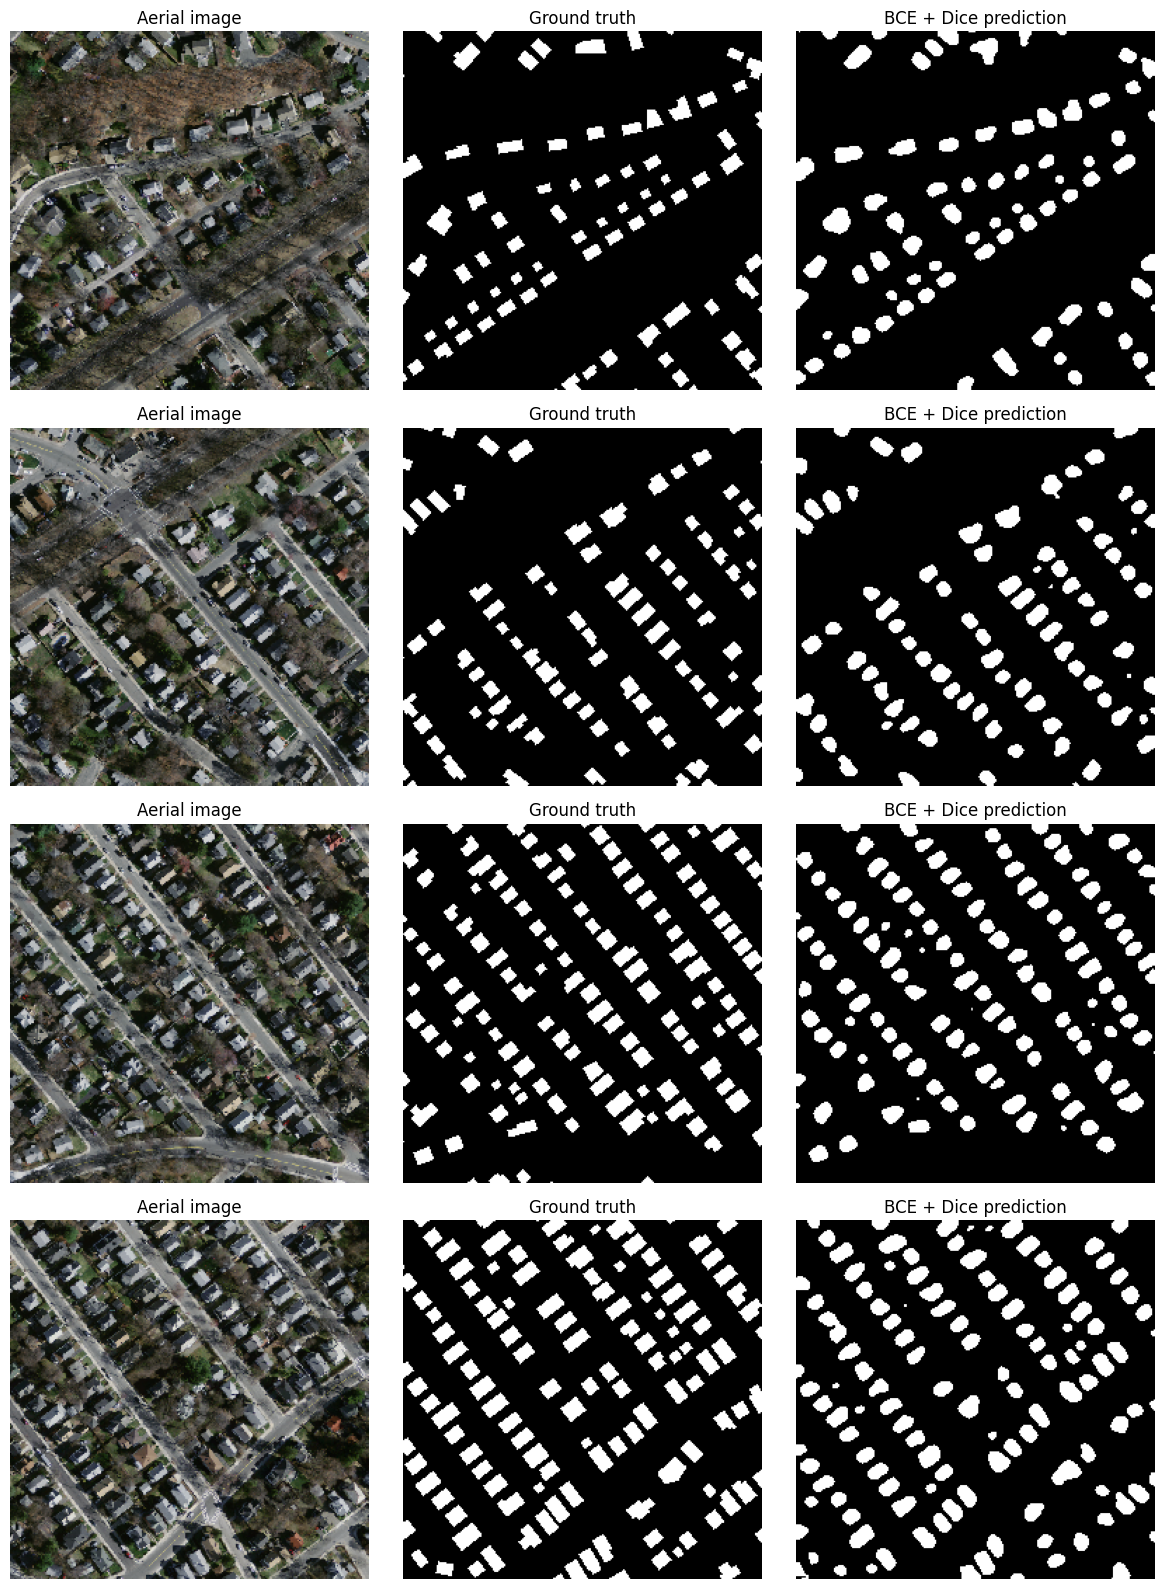

In [19]:
import matplotlib.pyplot as plt

NUM_EXAMPLES = 4

fig, axes = plt.subplots(
    NUM_EXAMPLES,
    3,
    figsize=(12, 4 * NUM_EXAMPLES)
)

for i in range(NUM_EXAMPLES):
    image = denormalize_image(images[i])
    image = image.permute(1, 2, 0).numpy()

    ground_truth = masks[i, 0].numpy()
    prediction = predictions[i, 0].numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Aerial image")

    axes[i, 1].imshow(ground_truth, cmap="gray")
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(prediction, cmap="gray")
    axes[i, 2].set_title("BCE + Dice prediction")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "comparison_examples.png", dpi=150, bbox_inches="tight")
plt.show()


In [20]:
from PIL import Image
import numpy as np

PREDICTIONS_DIR = (
    PROJECT_ROOT
    / "results"
    / "predictions"
)

PREDICTIONS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

for i in range(min(10, len(predictions))):
    prediction = predictions[i, 0].numpy()

    prediction_image = (
        prediction * 255
    ).astype(np.uint8)

    Image.fromarray(prediction_image).save(
        PREDICTIONS_DIR
        / f"comparison_prediction_{i:02d}.png"
    )


selected = test_df.iloc[:len(predictions)].copy()
selected["prediction_path"] = [
    f"results/predictions/comparison_prediction_{i:02d}.png" for i in range(len(selected))
]
selected.to_csv(METRICS_DIR / "comparison_selected_predictions.csv", index=False)


## Initial comparison

We compare validation and test IoU/Dice with the saved baseline results using
threshold 0.5 and global pixel totals. Changes are reported in percentage points.
BCE-only and combined loss values measure different objectives and are not
compared directly.


In [21]:
baseline_metrics = pd.read_csv(METRICS_DIR / "baseline_metrics.csv")
comparison_rows = []
for split, prefix in [("validation", "best_val"), ("test", "test")]:
    for metric in ["iou", "dice"]:
        column = f"{prefix}_{metric}"
        reference = float(baseline_metrics.iloc[0][column])
        current = float(comparison_metrics.iloc[0][column])
        comparison_rows.append({
            "split": split, "metric": metric,
            "baseline": reference, "bce_dice": current,
            "delta_percentage_points": 100 * (current - reference),
        })
initial_comparison = pd.DataFrame(comparison_rows)
initial_comparison.to_csv(METRICS_DIR / "comparison_initial_comparison.csv", index=False)
display(initial_comparison)


,split,metric,baseline,bce_dice,delta_percentage_points
0,validation,iou,0.633801,0.616017,-1.778369
1,validation,dice,0.775860,0.762389,-1.347122
2,test,iou,0.689807,0.668093,-2.171355
3,test,dice,0.816433,0.801026,-1.540648


In [22]:
CACHE_DIR = PROJECT_ROOT / "results" / "comparison_probabilities"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
export_started = time.perf_counter()
model.eval()
for split, loader, frame in [("val", val_loader, val_df), ("test", test_loader, test_df)]:
    chunks = []
    with torch.no_grad():
        for batch_images, _ in loader:
            batch_logits = model(batch_images.to(device, non_blocking=True))
            chunks.append(torch.sigmoid(batch_logits).cpu().numpy())
    np.savez_compressed(
        CACHE_DIR / f"{split}.npz",
        probabilities=np.concatenate(chunks, axis=0),
        image_paths=frame.image_path.to_numpy(dtype=str),
        mask_paths=frame.mask_path.to_numpy(dtype=str),
        source_images=frame.source_image.to_numpy(dtype=str),
        patch_indices=frame.patch_idx.to_numpy(),
    )
synchronize()
export_seconds = time.perf_counter() - export_started

manifest = {
    "status": "completed", "started_utc": RUN_STARTED_UTC,
    "completed_utc": datetime.now(timezone.utc).isoformat(),
    "baseline_commit": "2c418ba", "contributor": "Elena Tuturina",
    "research_question": "Does BCE + soft Dice improve building IoU/Dice over BCE?",
    "changed_factor": "loss", "loss": "BCEWithLogitsLoss + mean per-patch soft Dice loss",
    "loss_coefficients": [1, 1], "dice_smooth": 1.0,
    "architecture": "Unet", "encoder": "resnet18", "encoder_weights": "imagenet",
    "seed": SEED, "batch_size": BATCH_SIZE, "epochs": NUM_EPOCHS,
    "optimizer": "Adam", "learning_rate": 0.001, "threshold": 0.5,
    "checkpoint_selection": "minimum validation combined loss",
    "metric_aggregation": "global pixel totals; epsilon=1e-7",
    "data": DATA_SUMMARY, "environment": ENVIRONMENT,
    "checkpoint_path": str(MODEL_PATH.relative_to(PROJECT_ROOT)),
    "checkpoint_sha256": sha256(MODEL_PATH),
    "best_epoch": int(best_epoch_row["epoch"]),
    "training_seconds_including_epoch_validation": training_seconds,
    "test_evaluation_seconds_including_loading_and_metrics": test_evaluation_seconds,
    "test_evaluation_seconds_per_patch": test_evaluation_seconds / len(test_dataset),
    "probability_export_seconds_including_compression": export_seconds,
    "baseline_reference_sha256": sha256(METRICS_DIR / "baseline_metrics.csv"),
}
write_json(METRICS_DIR / "comparison_run.json", manifest)
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True, check=True)
(METRICS_DIR / "comparison_environment.txt").write_text(freeze.stdout, encoding="utf-8")
print("Results saved.")


Results saved.


## Comparison summary

The comparison changes only the loss function, from BCE to BCE + soft Dice.
Both conditions use:

- U-Net with an ImageNet-pretrained ResNet18 encoder;
- the original train/validation/test split: 4,932 / 144 / 360 patches;
- the same preprocessing and 256 × 256 input patches;
- Adam with learning rate 0.001, batch size 8 and 10 epochs;
- random seed 42 and prediction threshold 0.5.

Training history, metrics, selected predictions and runtime information are saved
under `results/`. The best checkpoint and validation/test probability maps are
saved locally for further evaluation. Example predictions are saved in `figures/`.

The baseline was trained on a T4 GPU. Hardware and software differences should
be considered when interpreting this single-run comparison.
